# Seminar 2 - Auto mpg

## Objectives

Undertake similar EDA with Auto-mpg dataset:

- Identify missing values.
- Estimate Skewness and Kurtosis.
- Correlation Heat Map.
- Scatter plot for different parameters.
- Replace categorical values with numerical values (i.e., America 1, Europe 2, etc.).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('Auto-mpg.csv')

In [4]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


# Missing Values

The above method df.info() shows that all the Data columns have no missing values.

However just for the purpouse of showing how to easily find missing value we will write the code.

In [6]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

As said no missing value among all the columns.

## How to deal Missing Values

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Dealing with Nan on a specific column

In [ ]:
df['horsepower'] = pd.to_numeric(
    df['horsepower'],
    errors='coerce'
) # Change Hp data type

missing_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')) # we input the way we want the simpler imputer deal the Nan
])

df['horsepower'] = missing_pipeline.fit_transform(
    df[['horsepower']]
)

# Dealining with Nan on multiple columns

In [27]:
numeric_features = [
    'mpg',
    'cylinders',
    'displacement',
    'horsepower',
    'weight',
    'acceleration',
    'model year',
    'origin'
]

missing_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

df[numeric_features] = missing_pipeline.fit_transform(
    df[numeric_features]
)

# Skew and Kurosis

We check **skewness** and **kurtosis** during exploratory data analysis because they help us understand the shape of the distribution and identify potential extreme values or **outliers**.

This is particularly useful before applying statistical methods or machine learning algorithms, as highly skewed distributions and extreme observations can influence the analysis and, in some cases, the resulting model or clusters.

## Skewness	

**What is that?**

Measures the asymmetry of a distribution.

**What Values can have?**

- ≈ 0	Approximately symmetric
- $>  0	Right-skewed → longer tail on the right
- $<  0	Left-skewed → longer tail on the left
- $> 1 or < -1	Strong skewness

## Positive Skew - right tail

mean is > than median > mode

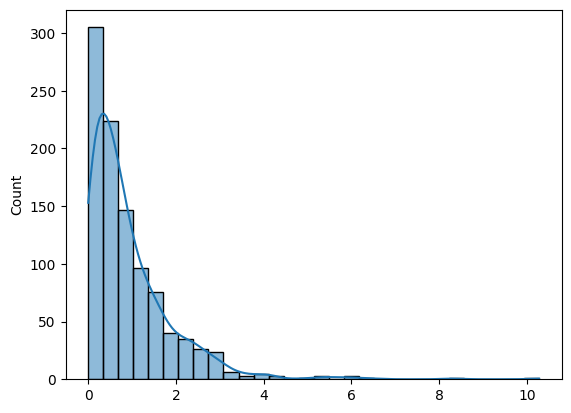

In [11]:
data = np.random.exponential(scale=1, size=1000)

sns.histplot(data, bins=30, kde=True)

plt.show()

## Negative Skew - left tail

mode is > than median > than mean 

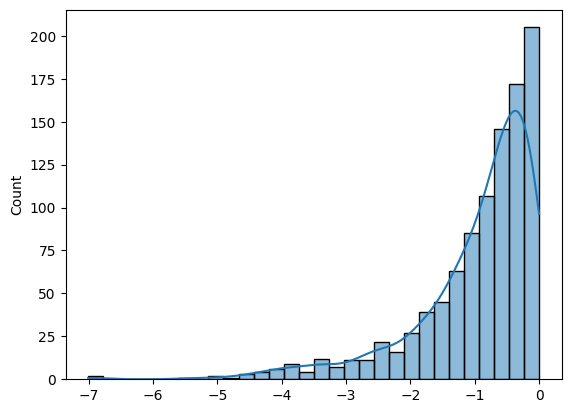

In [12]:
data = -np.random.exponential(scale=1, size=1000)

sns.histplot(data, bins=30, kde=True)

plt.show()

# Kurtosis

Kurtosis is used to understand the shape of a distribution, especially the weight of its tails and the presence of extreme values. It can therefore help identify whether a variable may contain unusually extreme observations.

## Kurtosis Values

- ≈ 0	Similar to a normal distribution
- $> 0	Heavier tails → more extreme values
- < 0	Lighter tails → fewer extreme values

# Negative Low

Low kurtosis → lighter tails and fewer extreme observations.

<Axes: ylabel='Density'>

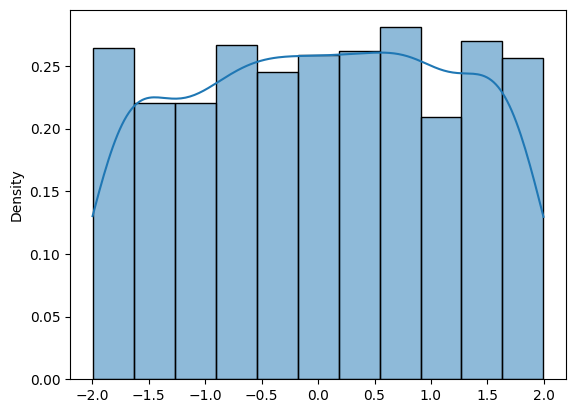

In [20]:
data_neg = np.random.uniform(-2,2,size=1000)

sns.histplot(data_neg, kde=True, stat='density')

## Positive High

High kurtosis → heavier tails and potentially more extreme observations.

<Axes: ylabel='Density'>

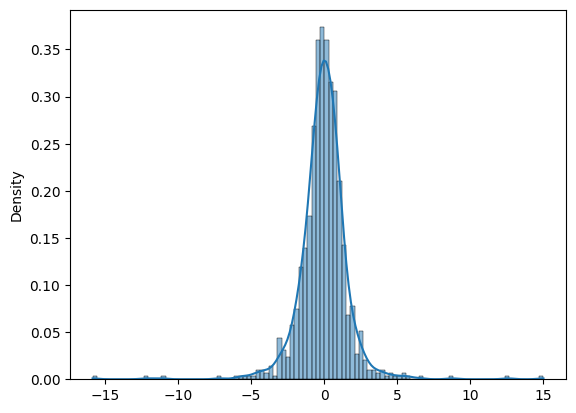

In [19]:
data_heavy = np.random.standard_t(df=3, size=1000)
sns.histplot(data_heavy, kde=True, stat='density')

In [9]:
numeric_stats = df.select_dtypes(include='number').agg(['skew','kurt'])
print(numeric_stats)

           mpg  cylinders  displacement    weight  acceleration  model year  \
skew  0.457066   0.526922      0.719645  0.531063      0.278777    0.011535   
kurt -0.510781  -1.376662     -0.746597 -0.785529      0.419497   -1.181232   

        origin  
skew  0.923776  
kurt -0.817597  


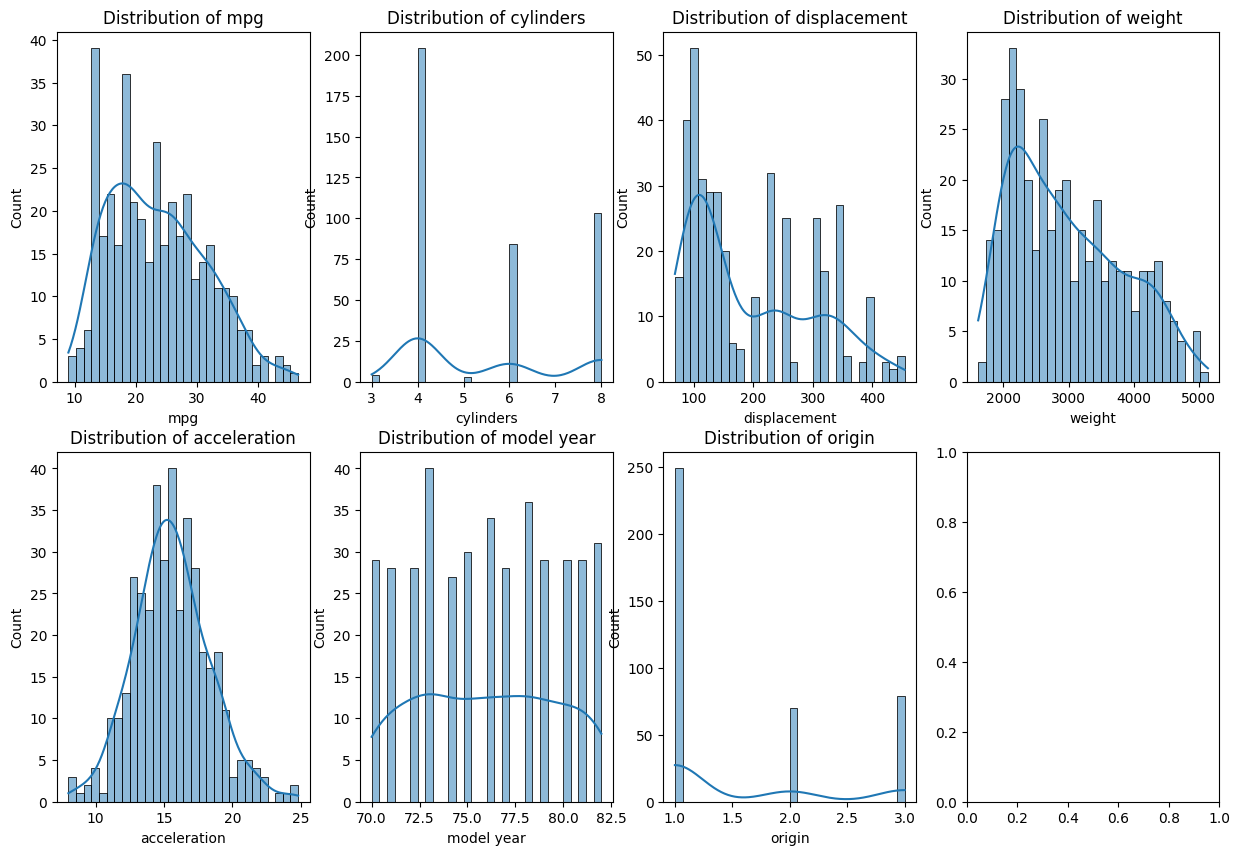

In [15]:
fig,axis=plt.subplots(2,4,figsize=(15,10))

for (col_name,series),ax in zip(numeric_stats.items(),axis.flat):
    sns.histplot(df[col_name],bins = 30,kde = True, ax = ax)
    ax.set_title(f'Distribution of {col_name}')
plt.show()

# Interpretation

- **MPG** (skew = 0.46): slightly right-skewed, but still fairly close to symmetric.

- **Cylinders** (0.53): moderately right-skewed, with some concentration towards lower values.

- **Displacement** (0.72): the most noticeably right-skewed numerical variable, suggesting some higher displacement values.

- **Weight** (0.53): moderately right-skewed.

- **Acceleration** (0.28): close to symmetric, with only a small positive skew.

- **Model year** (0.01): almost perfectly symmetric, with practically no skewness.

- **Origin** (0.92): the strongest positive skewness, although this variable should be interpreted carefully because it is a categorical/discrete variable encoded numerically.
Kurtosis

All variables except acceleration have negative kurtosis:

Negative kurtosis indicates lighter tails and fewer extreme observations compared with a normal distribution.
Acceleration has a kurtosis of 0.42, which is slightly positive, suggesting somewhat heavier tails.
Model year has the lowest kurtosis (-1.18), indicating a relatively flat distribution.

The variables show mostly positive skewness, indicating a mild to moderate right-skewed distribution. Displacement and origin show the highest skewness, while model year is almost symmetric. Kurtosis is generally negative, suggesting relatively light tails and a limited presence of extreme observations. Acceleration is the only variable with slightly positive kurtosis, indicating somewhat heavier tails.

# Correlation

Correlation is used to measure the strength and direction of the relationship between two variables. It is particularly useful during exploratory data analysis to identify variables that may be related and to detect possible multicollinearity before applying a model.

## Values

The Pearson correlation coefficient (r) ranges from -1 to +1:

- +1	Perfect positive correlation
- +0.7 to +1	Strong positive relationship
- +0.3 to +0.7	Moderate positive relationship
- 0	No linear relationship
- -0.3 to 0	Weak negative relationship
- -0.7 to -0.3	Moderate negative relationship
- -1 to -0.7	Strong negative relationship
- -1	Perfect negative correlation

In [23]:
df[numeric_stats.keys()].corr()

,mpg,cylinders,displacement,weight,acceleration,model year,origin
mpg,1.000000,-0.775396,-0.804203,-0.831741,0.420289,0.579267,0.563450
cylinders,-0.775396,1.000000,0.950721,0.896017,-0.505419,-0.348746,-0.562543
displacement,-0.804203,0.950721,1.000000,0.932824,-0.543684,-0.370164,-0.609409
weight,-0.831741,0.896017,0.932824,1.000000,-0.417457,-0.306564,-0.581024
acceleration,0.420289,-0.505419,-0.543684,-0.417457,1.000000,0.288137,0.205873
model year,0.579267,-0.348746,-0.370164,-0.306564,0.288137,1.000000,0.180662
origin,0.563450,-0.562543,-0.609409,-0.581024,0.205873,0.180662,1.000000


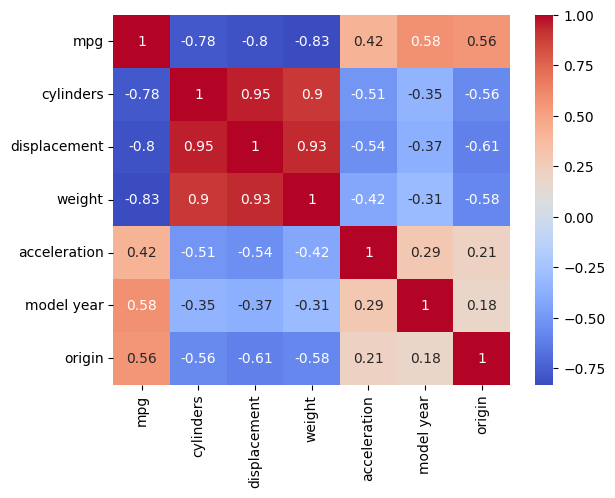

In [24]:
sns.heatmap( df[numeric_stats.keys()].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.show();

# Interpretation

MPG has a strong negative correlation with:

- weight → -0.83
- displacement → -0.80
- cylinders → -0.78

This means that cars with higher weight, displacement and number of cylinders tend to have lower MPG.

cylinders, displacement and weight are very strongly positively correlated with each other:

- cylinders ↔ displacement → 0.95
- displacement ↔ weight → 0.93
- cylinders ↔ weight → 0.90

This suggests that these variables contain quite similar information and could create multicollinearity if used together in a regression model.

Acceleration has a moderate positive correlation with mpg (0.42) and moderate negative correlations with cylinders (-0.51) and displacement (-0.54).
Model year has a moderate positive relationship with mpg (0.58), suggesting that newer cars tend to have better fuel efficiency.
Origin also has a moderate positive correlation with mpg (0.56) and negative correlations with cylinders, displacement and weight.

# Observation

The correlation analysis shows strong relationships between several variables. MPG has a strong negative correlation with weight, displacement and cylinders, while these three variables are also strongly positively correlated with each other. Model year and origin show moderate positive relationships with MPG. The strong correlations between cylinders, displacement and weight indicate potential multicollinearity, which should be considered when using these variables in predictive models.

# Replace categorical values with Numerical

## Pipeline

A Pipeline is used to organise multiple data processing steps into a single sequence. Each step is applied automatically in the correct order.

## Why do we use it?

- Keeps the preprocessing organised and consistent
- Avoids repeating code
- Reduces the risk of data leakage
- Ensures the same transformations are applied to training and test data
- Makes the ML workflow easier to reproduce


In [28]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [31]:
df['origin'] = df['origin'].astype(str)

In [32]:
column=df.columns

for col in column:
    print(f'{col} is {df[col].dtype}')

mpg is float64
cylinders is float64
displacement is float64
horsepower is float64
weight is float64
acceleration is float64
model year is float64
origin is object
car name is object


In [33]:
categorical_features = [
    'origin',
    'car name'
]

In [34]:
categorical_pipeline = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [35]:
X_categorical = categorical_pipeline.fit_transform(
    df[categorical_features]
)

In [39]:
X_categorical_columns = categorical_pipeline.named_steps['onehot'].get_feature_names_out(categorical_features) # take columns encoded


# At this point we crate a DF with columns X_categorical and values X_cateorical_columns 

In [41]:
X_categorical_df = pd.DataFrame(X_categorical.toarray(),columns=X_categorical_columns,
    index=df.index
)
X_categorical_df 

,origin_1.0,origin_2.0,origin_3.0,car name_amc ambassador brougham,car name_amc ambassador dpl,car name_amc ambassador sst,car name_amc concord,car name_amc concord d/l,car name_amc concord dl,car name_amc concord dl 6,...,car name_volvo 145e (sw),car name_volvo 244dl,car name_volvo 245,car name_volvo 264gl,car name_volvo diesel,car name_vw dasher (diesel),car name_vw pickup,car name_vw rabbit,car name_vw rabbit c (diesel),car name_vw rabbit custom
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
393,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
394,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
395,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
396,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [43]:
df1=df.copy()
df_encoded = pd.concat(
    [
        df1.drop(columns=categorical_features),
        X_categorical_df
    ],
    axis=1
)

In [44]:
df_encoded

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin_1.0,origin_2.0,origin_3.0,...,car name_volvo 145e (sw),car name_volvo 244dl,car name_volvo 245,car name_volvo 264gl,car name_volvo diesel,car name_vw dasher (diesel),car name_vw pickup,car name_vw rabbit,car name_vw rabbit c (diesel),car name_vw rabbit custom
0,18.0,8.0,307.0,130.0,3504.0,12.0,70.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,15.0,8.0,350.0,165.0,3693.0,11.5,70.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,18.0,8.0,318.0,150.0,3436.0,11.0,70.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,16.0,8.0,304.0,150.0,3433.0,12.0,70.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,17.0,8.0,302.0,140.0,3449.0,10.5,70.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
393,27.0,4.0,140.0,86.0,2790.0,15.6,82.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
394,44.0,4.0,97.0,52.0,2130.0,24.6,82.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
395,32.0,4.0,135.0,84.0,2295.0,11.6,82.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
396,28.0,4.0,120.0,79.0,2625.0,18.6,82.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
